In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math
import time
import random
from sklearn.metrics import accuracy_score

<p style="font-size:20px">My own model = sigmoid activation function, no regularization, SGD, no momentum</p>

In [2]:
from nn_functions import sigma, sigma_der, det_activations, grad, neural_network, nn_plot, predict

In [3]:
df = pd.read_csv('hearing_test.csv')
df.head()

,age,physical_score,test_result
0,33.0,40.7,1
1,50.0,37.2,1
2,52.0,24.7,0
3,56.0,31.0,0
4,35.0,42.9,1


In [4]:
labels = np.unique(df['test_result'])
labels

array([0, 1])

In [5]:
X = df.drop('test_result', axis=1)
y = df['test_result']

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=42)

In [8]:
scaler = StandardScaler()
scaled_X_train = scaler.fit_transform(X_train)
scaled_X_test = scaler.transform(X_test)

<p style="font-size:16px">y_train requires dummies for model to work (outputs have to be binary / multiclass), whereas for evaluation of accuracy y_test can be a 1D series. Something to fix later...</p>

In [9]:
y_train_d = np.array(pd.get_dummies(y_train, dtype=int))

Time taken: 7.65282416343689 seconds
Accuracy: 0.896


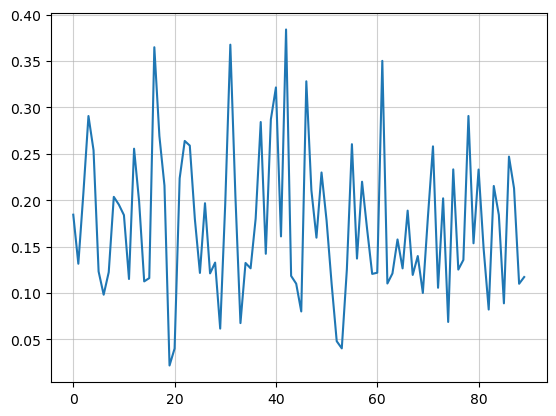

In [11]:
#inputs_train, outputs_train, inputs_test, outputs_test, labels, nodes, learning_rate, epochs, batch_size

weights, biases, cost = nn_plot(scaled_X_train, y_train_d, scaled_X_test, y_test, labels, [10, 10], 0.01, 10, 50, random_state=63)

Time taken: 22.4330997467041 seconds
Accuracy: 0.896


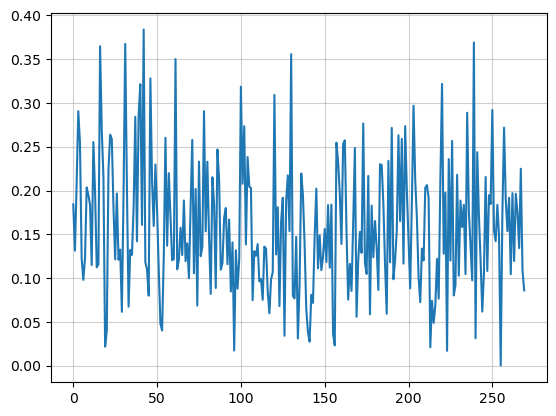

In [13]:
weights, biases, cost = nn_plot(scaled_X_train, y_train_d, scaled_X_test, y_test, labels, [10, 10], 0.01, 30, 50, random_state=63)

Time taken: 23.64756202697754 seconds
Accuracy: 0.894


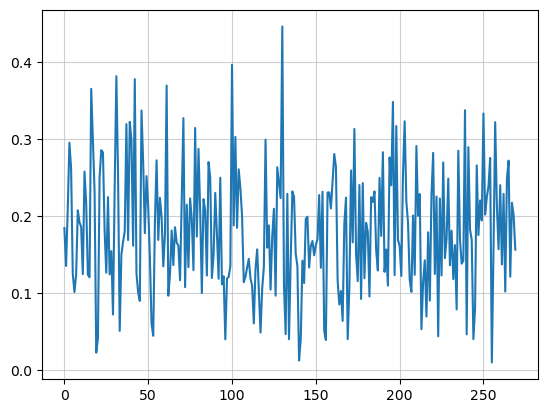

In [14]:
weights, biases, cost = nn_plot(scaled_X_train, y_train_d, scaled_X_test, y_test, labels, [10, 10], 0.001, 30, 50, random_state=63)

Time taken: 5.513169050216675 seconds
Accuracy: 0.886


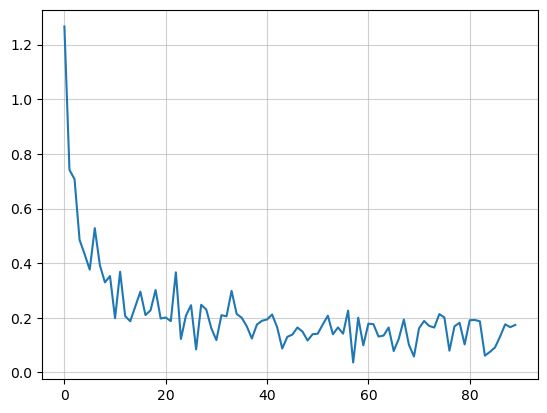

In [15]:
weights, biases, cost = nn_plot(scaled_X_train, y_train_d, scaled_X_test, y_test, labels, [5, 5], 0.1, 10, 50, random_state=63)

<p style="font-size:20px">MLPClassifier = relu activation function, regularization, SGD, momentum, Glorot/Xavier initialization</p>

In [16]:
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import GridSearchCV

In [17]:
mlp = MLPClassifier(hidden_layer_sizes=(10,10), learning_rate_init=0.01, solver='sgd', batch_size=50)

In [18]:
mlp.fit(scaled_X_train, y_train)

MLPClassifier(batch_size=50, hidden_layer_sizes=(10, 10),
              learning_rate_init=0.01, solver='sgd')

In [19]:
y_pred = mlp.predict(scaled_X_test)

In [20]:
accuracy_score(y_pred, y_test)

0.914

In [21]:
mlp = MLPClassifier(max_iter=10000, random_state=42, batch_size=50, solver='sgd') 

param_grid = {'hidden_layer_sizes': [(5,), (10,), (15,), (5,5), (10, 10), (15, 15)],
              'learning_rate_init': [0.001, 0.01, 0.1]}

grid_mlp = GridSearchCV(mlp, param_grid=param_grid)

grid_mlp.fit(scaled_X_train, y_train)
grid_mlp.best_params_

{'hidden_layer_sizes': (10,), 'learning_rate_init': 0.01}

In [22]:
y_pred = grid_mlp.predict(scaled_X_test)
accuracy_score(y_pred, y_test)

0.912

<p style="font-size:20px">PyTorch</p>

In [23]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import torch.optim as optim

In [65]:
y_test_d = np.array(pd.get_dummies(y_test, dtype=int))

In [66]:
dataset_train = TensorDataset(torch.tensor(scaled_X_train), torch.tensor(y_train_d))
dataloader_train = DataLoader(dataset_train, batch_size=50, shuffle=True)

dataset_test = TensorDataset(torch.tensor(scaled_X_test).float(), torch.tensor(y_test_d))
dataloader_test = DataLoader(dataset_test, batch_size=len(dataset_test), shuffle=True)

#features = torch.tensor(scaled_X_test).float()

In [80]:
def run_model(model):

    start = time.time()  

    training_loss = []
    validation_loss = []
    
    for i in range(num_epochs):

        model.train()
        t_loss = 0
        
        for data in dataloader_train:
            optimizer.zero_grad()
            feature, target = data
            target = target.float()
            feature = feature.float()
            prediction = model(feature)    
            loss = criterion(prediction, target)   
            t_loss += loss.item()
            loss.backward()
            optimizer.step()

        training_loss.append(t_loss/len(dataloader))

        model.eval()
    
        with torch.no_grad():
            for feature, target in dataloader_test:
                prediction = model(feature)   
                loss = criterion(prediction, target)
                validation_loss.append(loss.item())
                break
        
    end = time.time()
    print("Time taken:", round(end-start, 3), "seconds")

    features = torch.tensor(scaled_X_test).float()
    
    with torch.no_grad():
        logits = model(features)   
        preds = torch.argmax(logits, dim=1)
    
    y_pred = pd.Series(preds.numpy()) 
    print('Accuracy score: ' + str(accuracy_score(y_pred, y_test)))
    print('')

    plt.figure(figsize=(5,3))
    plt.plot(np.arange(1, num_epochs+1), training_loss, label="training loss");
    plt.plot(np.arange(1, num_epochs+1), validation_loss, label="validation loss");
    plt.grid(alpha=0.6);
    plt.xticks(fontsize=8);
    plt.yticks(fontsize=8);
    plt.legend();

Time taken: 2.213 seconds
Accuracy score: 0.908



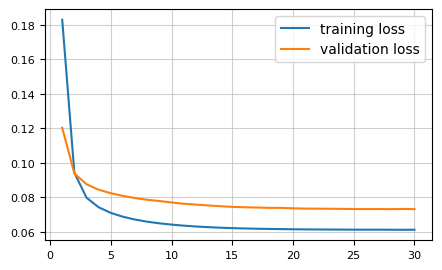

In [81]:
model = nn.Sequential(nn.Linear(2,5), nn.Linear(5,5), nn.Linear(5,2), nn.Sigmoid())
optimizer = optim.SGD(model.parameters(), lr=0.1)
criterion = nn.MSELoss()
num_epochs = 30

run_model(model)

Time taken: 6.586 seconds
Accuracy score: 0.906



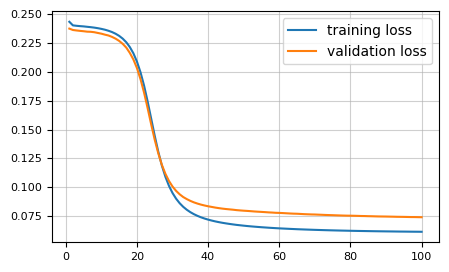

In [83]:
model = nn.Sequential(nn.Linear(2,5), nn.Sigmoid(), nn.Linear(5,5), nn.Sigmoid(), nn.Linear(5,2), nn.Sigmoid())
optimizer = optim.SGD(model.parameters(), lr=0.1)
criterion = nn.MSELoss()
num_epochs = 100

run_model(model)

Time taken: 7.498 seconds
Accuracy score: 0.904



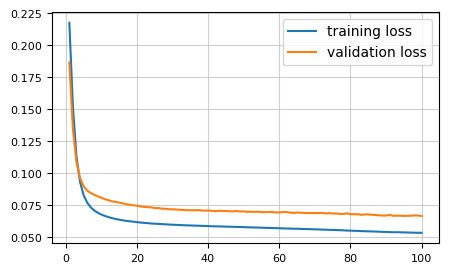

In [84]:
model = nn.Sequential(nn.Linear(2,5), nn.ReLU(), nn.Linear(5,5), nn.ReLU(), nn.Linear(5,2), nn.Sigmoid())
optimizer = optim.SGD(model.parameters(), lr=0.1)
criterion = nn.MSELoss()
num_epochs = 100

run_model(model)

Time taken: 237.019 seconds
Accuracy score: 0.914



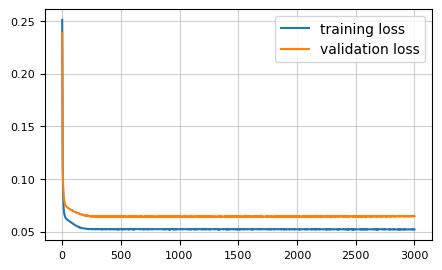

In [85]:
model = nn.Sequential(nn.Linear(2,5), nn.ReLU(), nn.Linear(5,5), nn.ReLU(), nn.Linear(5,2), nn.Sigmoid())
optimizer = optim.SGD(model.parameters(), lr=0.1)
criterion = nn.MSELoss()
num_epochs = 3000

run_model(model)

In [47]:
input_tensor = torch.tensor([[2.0, 2.0], [3.0, 4.0]])
softmax = nn.Softmax(dim=-1)
output_tensor = softmax(input_tensor)

print(output_tensor)

tensor([[0.5000, 0.5000],
        [0.2689, 0.7311]])


Time taken: 24.553 seconds
Accuracy score: 0.914



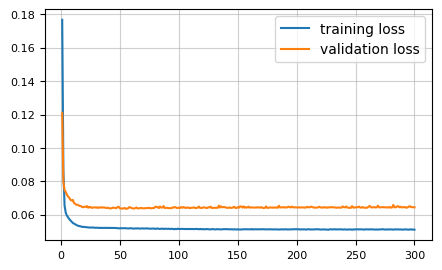

In [86]:
model = nn.Sequential(nn.Linear(2,5), nn.ReLU(), nn.Linear(5,5), nn.ReLU(), nn.Linear(5,2), nn.Softmax(dim=-1))
optimizer = optim.SGD(model.parameters(), lr=0.1)
criterion = nn.MSELoss()
num_epochs = 300

run_model(model)

Time taken: 24.813 seconds
Accuracy score: 0.916



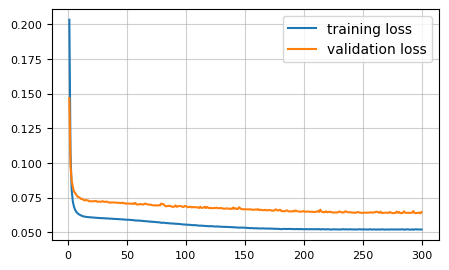

In [89]:
model = nn.Sequential(nn.Linear(2,5), nn.LeakyReLU(negative_slope=0.05), nn.Linear(5,5), nn.LeakyReLU(negative_slope=0.05), nn.Linear(5,2), 
                      nn.Softmax(dim=-1))
optimizer = optim.SGD(model.parameters(), lr=0.1)
criterion = nn.MSELoss()
num_epochs = 300

run_model(model)

Time taken: 24.937 seconds
Accuracy score: 0.916



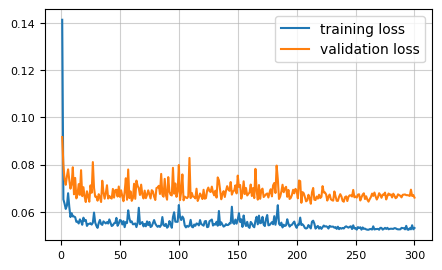

In [90]:
model = nn.Sequential(nn.Linear(2,5), nn.LeakyReLU(negative_slope=0.05), nn.Linear(5,5), nn.LeakyReLU(negative_slope=0.05), nn.Linear(5,2), 
                      nn.Softmax(dim=-1))
optimizer = optim.SGD(model.parameters(), lr=0.1, momentum=0.95)
criterion = nn.MSELoss()
num_epochs = 300

run_model(model)